# 0.1 Root Finding in One Dimension

## Setup

In [1]:
import matplotlib.pyplot as plt
import matplotlib.collections as mcl
import numpy as np
import pandas as pd

In [2]:
from collections.abc import Callable
from typing import NamedTuple
import numpy.typing as npt

In [3]:
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r'\usepackage{amsmath}\usepackage{mathtools}\usepackage{permute}\usepackage[notrig]{physics}\input{macros.tex}',
})

In [4]:
plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 600,
    "savefig.transparent": True,
    "savefig.bbox": 'tight',
})

## Question 1

In [5]:
x: npt.ArrayLike = np.arange(-4.0, -1.0, 0.01)
y1: npt.ArrayLike = 2 * x + 5
y2: npt.ArrayLike = 3 * np.sin(x)

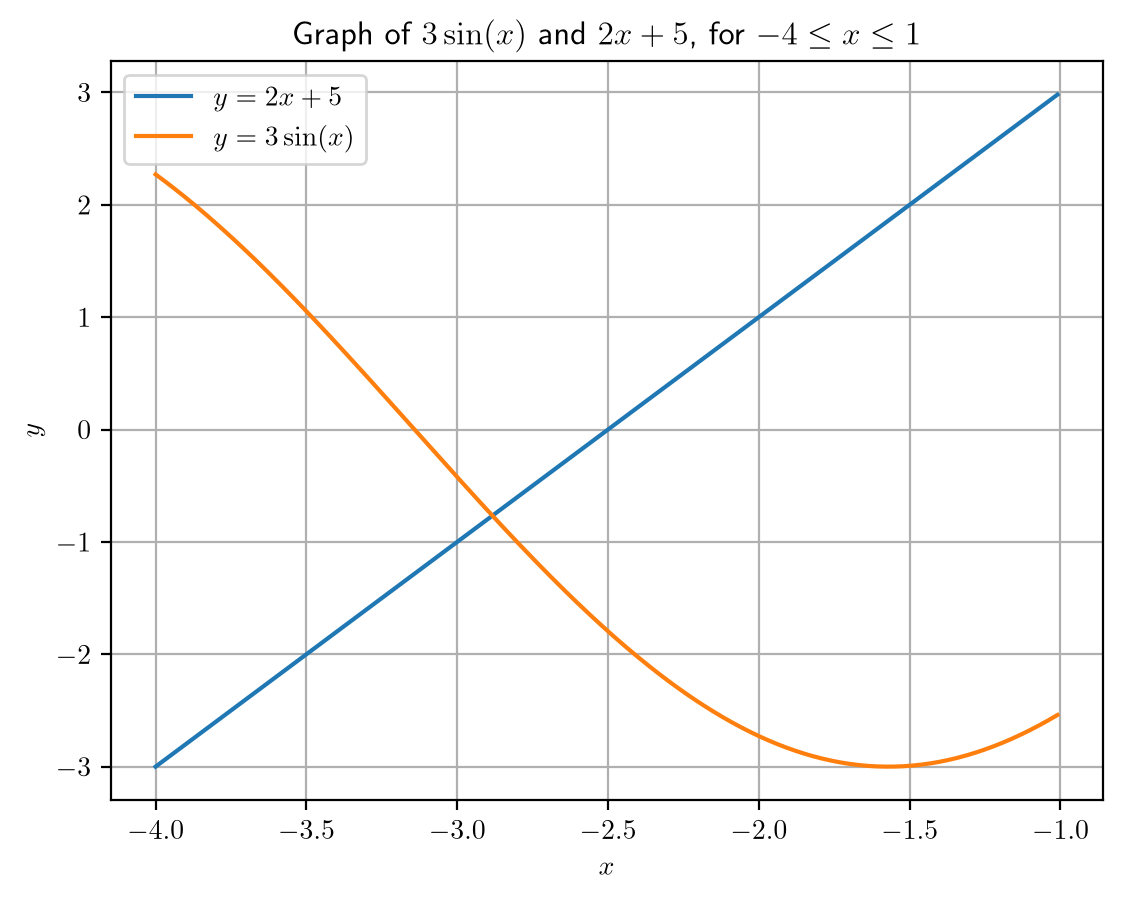

In [6]:
fig, ax = plt.subplots()

ax.plot(x, y1, label=r'\(y = 2x + 5\)')
ax.plot(x, y2, label=r'\(y = 3 \sin \pqty{x}\)')

ax.set(xlabel=r'\(x\)',
       ylabel=r'\(y\)',
       title=r'Graph of \(3 \sin \pqty{x}\) and \(2x + 5\), for \(-4 \leq x \leq 1\)')
ax.grid()
ax.legend()

fig.savefig('../fig/question-1')

## Programming Task: Binary Search

In [7]:
F = lambda x: 2 * x - 3 * np.sin(x) + 5

In [8]:
class BinarySearchResult(NamedTuple):
    iteration_count: int # number of iterations
    root_estimate: float # estimate of root
    error: float # truncation error

In [9]:
def binary_search(
    function: Callable[[float], float], # function for binary search
    left_endpoint: float, # starting left-endpoint
    right_endpoint: float, # starting right-endpoint
    truncation_error: float = 5e-6, # truncation error
    max_iteration: int = 1000 # max iterations
) -> BinarySearchResult:
    iteration: int = 0

    if function(right_endpoint) == 0:
        return BinarySearchResult(0, right_endpoint, 0)
    
    if function(left_endpoint) == 0:
        return BinarySearchResult(0, right_endpoint, 0)

    incr: int

    if function(right_endpoint) > 0 and function(left_endpoint) < 0: # increasing
        incr = 1
    elif function(right_endpoint) < 0 and function(left_endpoint) > 0: # decreasing
        incr = -1
    else:
        raise ValueError
    
    while (np.abs(right_endpoint - left_endpoint) >= 2 * truncation_error) and (iteration < max_iteration):
        iteration += 1

        midpoint: float = (left_endpoint + right_endpoint) / 2

        if function(midpoint) * incr > 0: # on the left
            right_endpoint = midpoint
        elif function(midpoint) * incr < 0: # on the right
            left_endpoint = midpoint
        else: # = 0
            return BinarySearchResult(iteration, midpoint, 0)

    return BinarySearchResult(iteration, (right_endpoint + left_endpoint) / 2, np.abs(right_endpoint - left_endpoint) / 2)

In [10]:
print(binary_search(F, -3, -2))
print(binary_search(F, -np.pi, 0))
print(binary_search(F, -10, 10))

print(binary_search(F, -4, -1))

BinarySearchResult(iteration_count=17, root_estimate=-2.8832359313964844, error=np.float64(3.814697265625e-06))
BinarySearchResult(iteration_count=19, root_estimate=-2.883239729136342, error=np.float64(2.9960562262232315e-06))
BinarySearchResult(iteration_count=21, root_estimate=-2.8832387924194336, error=np.float64(4.76837158203125e-06))
BinarySearchResult(iteration_count=19, root_estimate=-2.883236885070801, error=np.float64(2.86102294921875e-06))


## What is the Root Itself? [To the best of Float]

In [11]:
result: BinarySearchResult = binary_search(F, -3, -2, truncation_error=0)
x_ast: float = result.root_estimate
print(result.error, x_ast)

0 -2.8832368725582835


## Programming Task: Fixed-Point Iteration

In [12]:
class IterationProcess(NamedTuple):
    iteration: int # current iteration
    current_root_estimate: float # current value

In [13]:
def fixed_point_iteration(
    function: Callable[[float], float], # function for fixed point iteration
    x: float, # starting value
    term_difference: float = 1e-5, # end term difference
    max_iteration: int = 1000 # max iterations
) -> list[IterationProcess]:
    iteration: int = 0
    result: list[IterationProcess] = [IterationProcess(iteration, x)]

    while (iteration == 0 or
           np.abs(result[-1].current_root_estimate - result[-2].current_root_estimate) >= term_difference) and (iteration < max_iteration):
        iteration += 1

        x = function(x)
        result.append(IterationProcess(iteration, x))

    return result

## Question 3

In [14]:
fk = lambda x, k: (3 * np.sin(x) + k * x - 5) / (2 + k)
dfk = lambda x, k: (3 * np.cos(x) + k) / (2 + k)

In [15]:
def fixed_point_iteration_coordinates(root_estimate: pd.DataFrame,
                             function: Callable[[float], float],
                             length: int=-1) -> pd.DataFrame: # convert iteration process to coordinates
    if length == -1:
        length = len(root_estimate.index)
    iteration_process = pd.DataFrame(index=np.arange(0, 2 * length), columns=["x", "y"])

    for i in range(length):
        x: float = root_estimate.current_root_estimate[i]

        if i != 0:
            iteration_process.iloc[2 * i] = (x, x)
            
        iteration_process.iloc[2 * i + 1] = (x, function(x))

    return iteration_process

In [16]:
def plot_fixed_point_iteration_graph(function,
                         root_estimate: pd.DataFrame,
                         x: npt.ArrayLike,
                         initial_guess: float,
                         root: float,
                         title: str) -> None:
    iteration_process: pd.DataFrame = fixed_point_iteration_coordinates(root_estimate, function)
    y: npt.ArrayLike = function(x)

    ax.plot(x, x, label=r'\(y = x\)')
    ax.plot(x, y, label=r'\(y = f\pqty{x}\)')

    ax.plot(initial_guess, function(initial_guess), marker='+', color='g')
    ax.plot(iteration_process.x,
            iteration_process.y,
            label='Iteration Process',
            marker=',', linewidth=0.5, color='g')

    ax.plot(root, root, marker='+', color='r')

    ax.set(xlabel=r'\(x\)',
        ylabel=r'\(y\)',
        title=title)
    ax.grid()
    ax.legend()

In [17]:
def truncation_errors(function,
                      root_estimate: pd.DataFrame,
                      root: float) -> pd.DataFrame:
    truncation_errors: pd.DataFrame = pd.DataFrame(root_estimate).drop(columns=["iteration"])

    truncation_errors["function_value"] = function(truncation_errors["current_root_estimate"])
    truncation_errors["truncation_error"] = truncation_errors["current_root_estimate"] - root
    truncation_errors["truncation_ratio"] = truncation_errors["truncation_error"] / truncation_errors["truncation_error"].shift(1)

    
    return truncation_errors

### (i): non-convergence

In [18]:
f = lambda x: fk(x, 0)
df = lambda x: dfk(x, 0)

In [19]:
root_estimate = pd.DataFrame(fixed_point_iteration(f, -2, 1e-5, 10))
root_estimate

,iteration,current_root_estimate
0,0,-2.000000
1,1,-3.863946
2,2,-1.508272
3,3,-3.997069
4,4,-1.367675
5,5,-3.969163
6,6,-1.395566
7,7,-3.977030
8,8,-1.387615
9,9,-3.974904


In [20]:
data: pd.DataFrame = truncation_errors(f, root_estimate, x_ast)
data.to_csv('../data/question-3-i.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio
0,-2.000000,-3.863946,0.883237,NaN
1,-3.863946,-1.508272,-0.980709,-1.110358
2,-1.508272,-3.997069,1.374965,-1.402011
3,-3.997069,-1.367675,-1.113832,-0.810080
4,-1.367675,-3.969163,1.515562,-1.360674
5,-3.969163,-1.395566,-1.085926,-0.716517
6,-1.395566,-3.977030,1.487671,-1.369956
7,-3.977030,-1.387615,-1.093793,-0.735239
8,-1.387615,-3.974904,1.495622,-1.367372
9,-3.974904,-1.389757,-1.091667,-0.729909


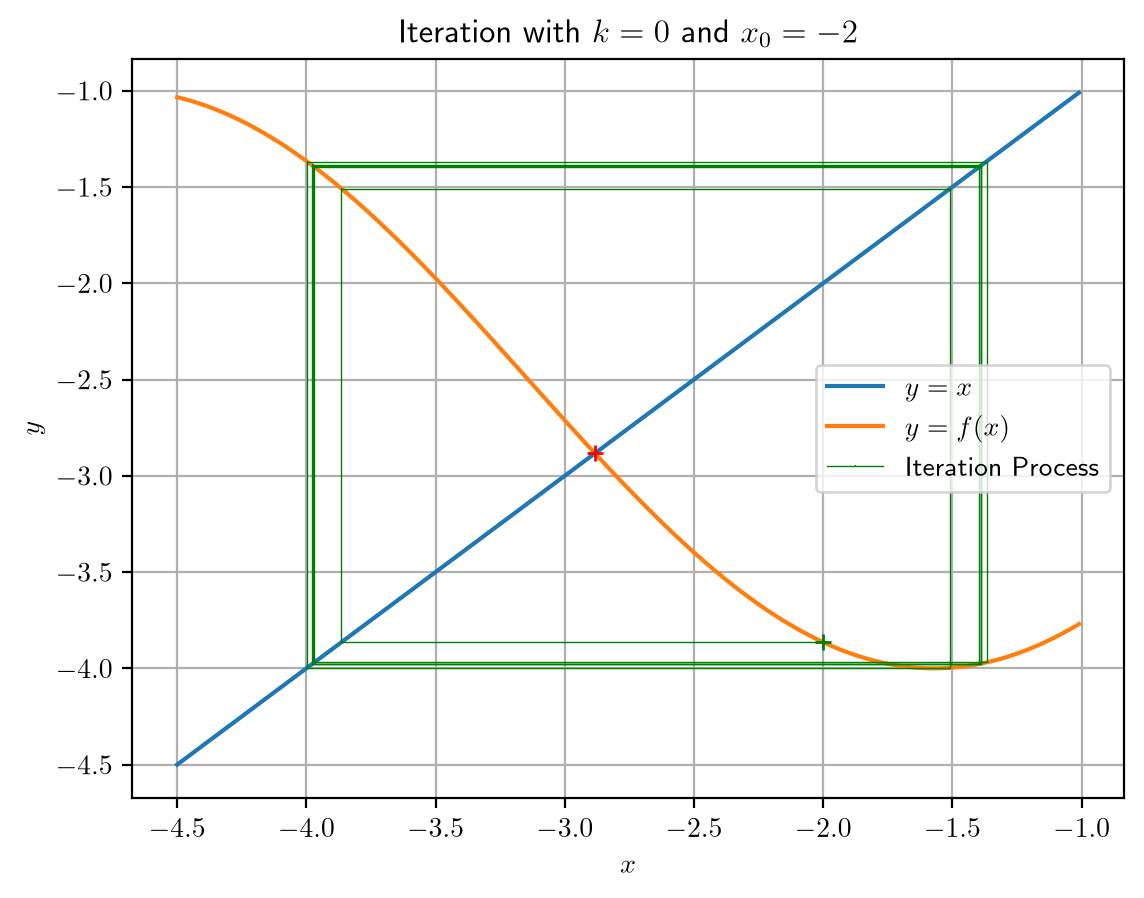

In [21]:
fig, ax = plt.subplots()
plot_fixed_point_iteration_graph(f,
                     root_estimate,
                     np.arange(-4.5, -1.0, 0.01),
                     -2,
                     x_ast,
                     r'Iteration with \(k = 0\) and \(x_0 = -2\)')

fig.savefig('../fig/question-3-i')

In [22]:
df(x_ast)

np.float64(-1.450217052551702)

### (iii): Monotonic Convergence

In [23]:
dfk(x_ast, 3)

np.float64(0.019913178979319213)

In [24]:
f = lambda x: fk(x, 3)
root_estimate = pd.DataFrame(fixed_point_iteration(f, -2, 1e-5, 20))
root_estimate

,iteration,current_root_estimate
0,0,-2.000000
1,1,-2.745578
2,2,-2.878794
3,3,-2.883147
4,4,-2.883235
5,5,-2.883237


In [25]:
data: pd.DataFrame = truncation_errors(f, root_estimate, x_ast)
data.to_csv('../data/question-3-iii-1.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio
0,-2.000000,-2.745578,8.832369e-01,NaN
1,-2.745578,-2.878794,1.376584e-01,0.155857
2,-2.878794,-2.883147,4.443344e-03,0.032278
3,-2.883147,-2.883235,9.000286e-05,0.020256
4,-2.883235,-2.883237,1.792864e-06,0.019920
5,-2.883237,-2.883237,3.570187e-08,0.019913


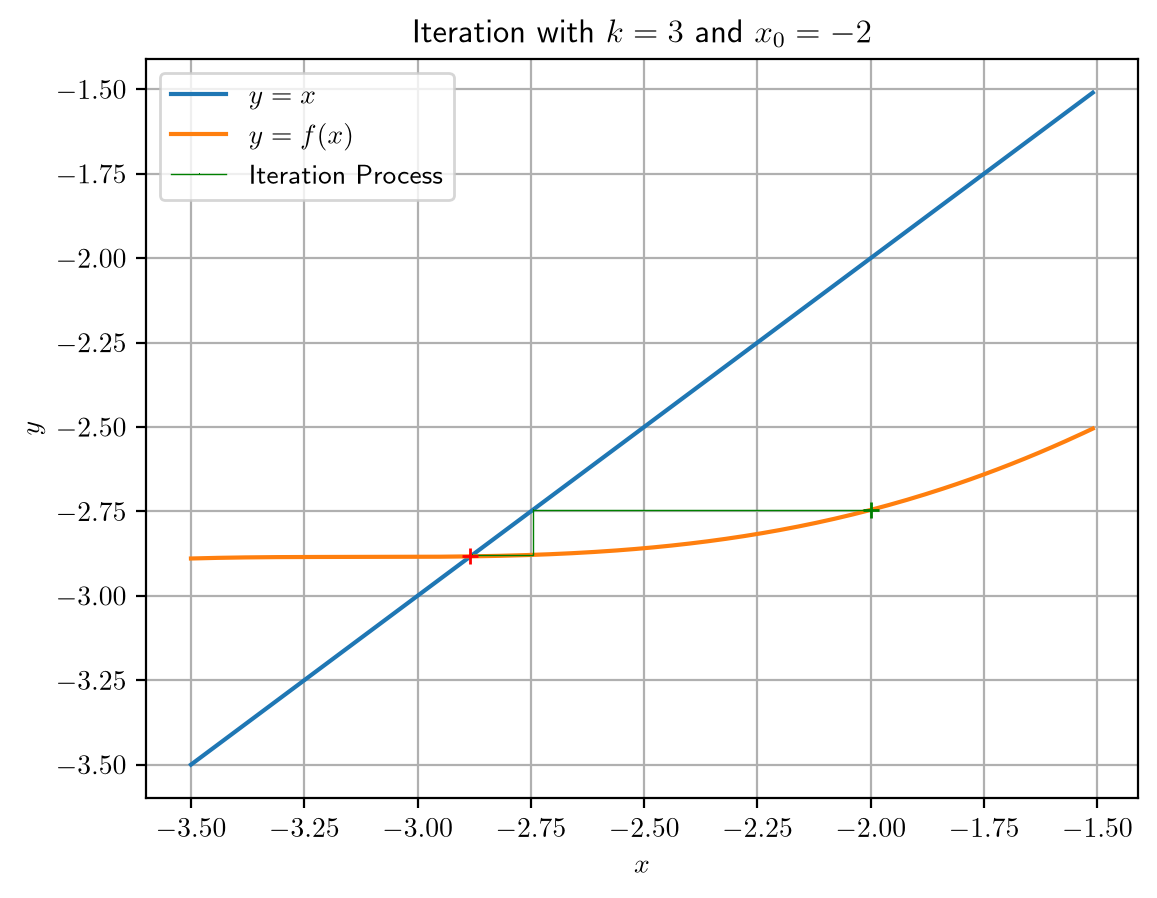

In [26]:
fig, ax = plt.subplots()
plot_fixed_point_iteration_graph(f,
                     root_estimate,
                     np.arange(-3.5, -1.5, 0.01),
                     -2,
                     x_ast,
                     r'Iteration with \(k = 3\) and \(x_0 = -2\)')

fig.savefig('../fig/question-3-iii-1')

### (iii): Oscillatory Convergence

In [27]:
dfk(x_ast, 1)

np.float64(-0.633478035034468)

In [28]:
f = lambda x: fk(x, 1)
root_estimate = pd.DataFrame(fixed_point_iteration(f, -2, 1e-5, 20))
root_estimate

,iteration,current_root_estimate
0,0,-2.000000
1,1,-3.242631
2,2,-2.646677
3,3,-3.023850
4,4,-2.792088
5,5,-2.939795
6,6,-2.847029
7,7,-2.905999
8,8,-2.868753
9,9,-2.892384


In [29]:
data: pd.DataFrame = truncation_errors(f, root_estimate, x_ast)
data.to_csv('../data/question-3-iii-2.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio
0,-2.000000,-3.242631,0.883237,NaN
1,-3.242631,-2.646677,-0.359394,-0.406905
2,-2.646677,-3.023850,0.236560,-0.658218
3,-3.023850,-2.792088,-0.140613,-0.594407
4,-2.792088,-2.939795,0.091149,-0.648228
5,-2.939795,-2.847029,-0.056558,-0.620504
6,-2.847029,-2.905999,0.036208,-0.640186
7,-2.905999,-2.868753,-0.022762,-0.628642
8,-2.868753,-2.892384,0.014483,-0.636302
9,-2.892384,-2.877431,-0.009148,-0.631594


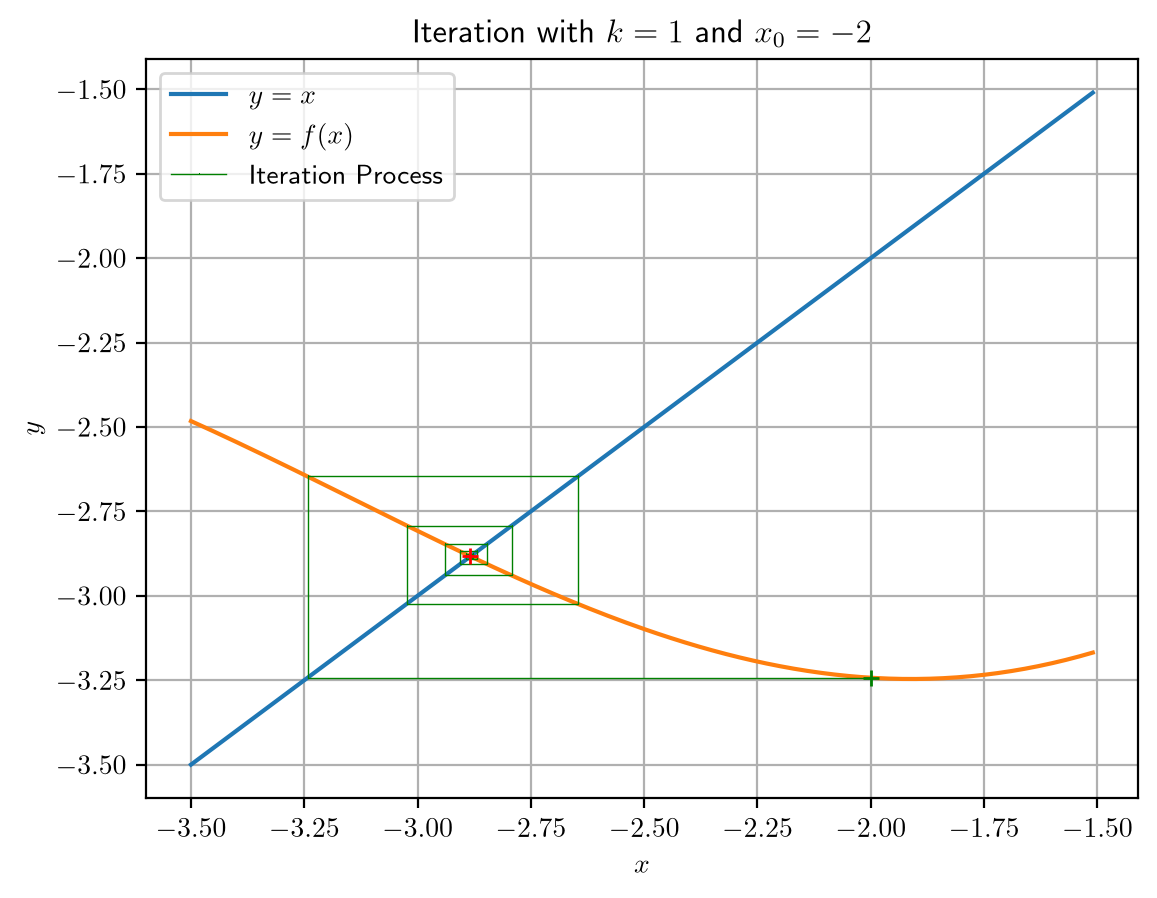

In [30]:
fig, ax = plt.subplots()
plot_fixed_point_iteration_graph(f,
                     root_estimate,
                     np.arange(-3.5, -1.5, 0.01),
                     -2,
                     x_ast,
                     r'Iteration with \(k = 1\) and \(x_0 = -2\)')

fig.savefig('../fig/question-3-iii-2')

### (iv): slow convergence

In [31]:
f = lambda x: fk(x, 16)
df = lambda x: dfk(x, 16)

root_estimate = pd.DataFrame(fixed_point_iteration(f, -2, 1e-5, 50))
root_estimate

,iteration,current_root_estimate
0,0,-2.000000
1,1,-2.207105
2,2,-2.373698
3,3,-2.503502
4,4,-2.602390
5,5,-2.676589
6,6,-2.731705
7,7,-2.772378
8,8,-2.802261
9,9,-2.824153


In [32]:
data: pd.DataFrame = truncation_errors(f, root_estimate, x_ast)
data.to_csv('../data/question-3-iv.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio
0,-2.000000,-2.207105,0.883237,NaN
1,-2.207105,-2.373698,0.676132,0.765516
2,-2.373698,-2.503502,0.509539,0.753609
3,-2.503502,-2.602390,0.379735,0.745252
4,-2.602390,-2.676589,0.280847,0.739587
5,-2.676589,-2.731705,0.206648,0.735804
6,-2.731705,-2.772378,0.151531,0.733282
7,-2.772378,-2.802261,0.110859,0.731590
8,-2.802261,-2.824153,0.080976,0.730441
9,-2.824153,-2.840158,0.059084,0.729653


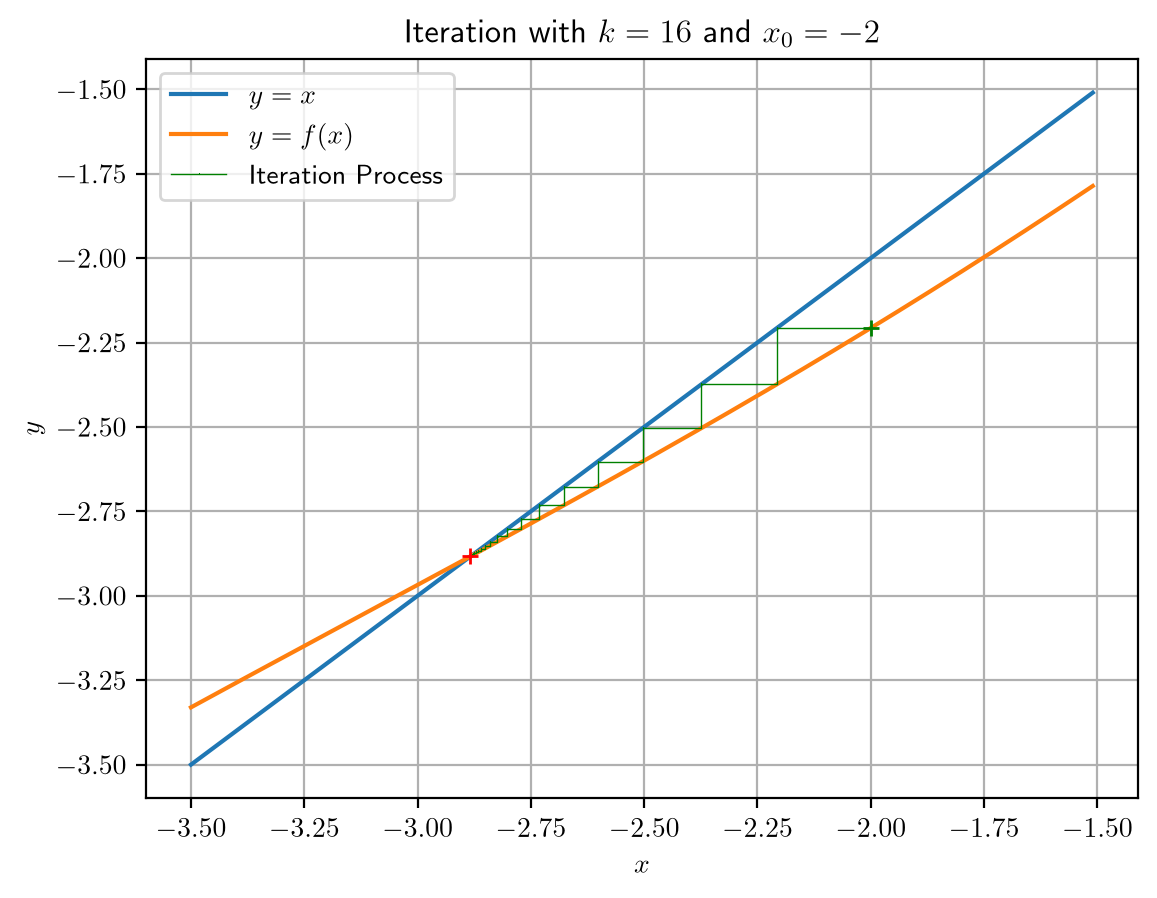

In [33]:
fig, ax = plt.subplots()
plot_fixed_point_iteration_graph(f,
                     root_estimate,
                     np.arange(-3.5, -1.5, 0.01),
                     -2,
                     x_ast,
                     r'Iteration with \(k = 16\) and \(x_0 = -2\)')

fig.savefig('../fig/question-3-iv')

In [34]:
root_estimate.iloc[-1].current_root_estimate - x_ast

np.float64(2.1084511679703155e-05)

In [35]:
df(-3), df(-2)

(np.float64(0.7238901394554813), np.float64(0.8195310827976985))

In [36]:
0.75 * (0.72 ** 34), 1 * (0.82 ** 34)

(1.0577088594564252e-05, 0.0011740077965196548)

In [37]:
dd: float = df(x_ast)
dd

np.float64(0.7277536608275886)

In [38]:
np.abs(1e-5 * dd / (dd - 1))

np.float64(2.6731439733582912e-05)

###  (v): rate of convergence

In [39]:
dfk(x_ast, 3), dfk(x_ast, 1), dfk(x_ast, 16)

(np.float64(0.019913178979319213),
 np.float64(-0.633478035034468),
 np.float64(0.7277536608275886))

## Question 4

In [40]:
f = lambda x: (- np.pow(x, 3) + 8.5 * np.pow(x, 2) + 8) / 20
df = lambda x: (- 3 * np.pow(x, 2) + 17 * x) / 20
d2f = lambda x: (- 6 * x + 17) / 20

In [41]:
root_estimate = pd.DataFrame(fixed_point_iteration(f, 5, 1e-10, 5000))
root_estimate

,iteration,current_root_estimate
0,0,5.000000
1,1,4.775000
2,2,4.646616
3,3,4.559929
4,4,4.496285
...,...,...
4996,4996,4.001138
4997,4997,4.001138
4998,4998,4.001138
4999,4999,4.001138


In [42]:
data: pd.DataFrame = truncation_errors(f, root_estimate, 4)
data['40/(7N e)'] = 40 / (7 * data.index * data.truncation_error)
data.to_csv('../data/question-4.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio,40/(7N e)
0,5.000000,4.775000,1.000000,NaN,inf
1,4.775000,4.646616,0.775000,0.775000,7.373272
2,4.646616,4.559929,0.646616,0.834344,4.418606
3,4.559929,4.496285,0.559929,0.865936,3.401793
4,4.496285,4.447071,0.496285,0.886336,2.878529
...,...,...,...,...,...
4996,4.001138,4.001138,0.001138,0.999801,1.004688
4997,4.001138,4.001138,0.001138,0.999801,1.004687
4998,4.001138,4.001138,0.001138,0.999801,1.004686
4999,4.001138,4.001138,0.001138,0.999801,1.004685


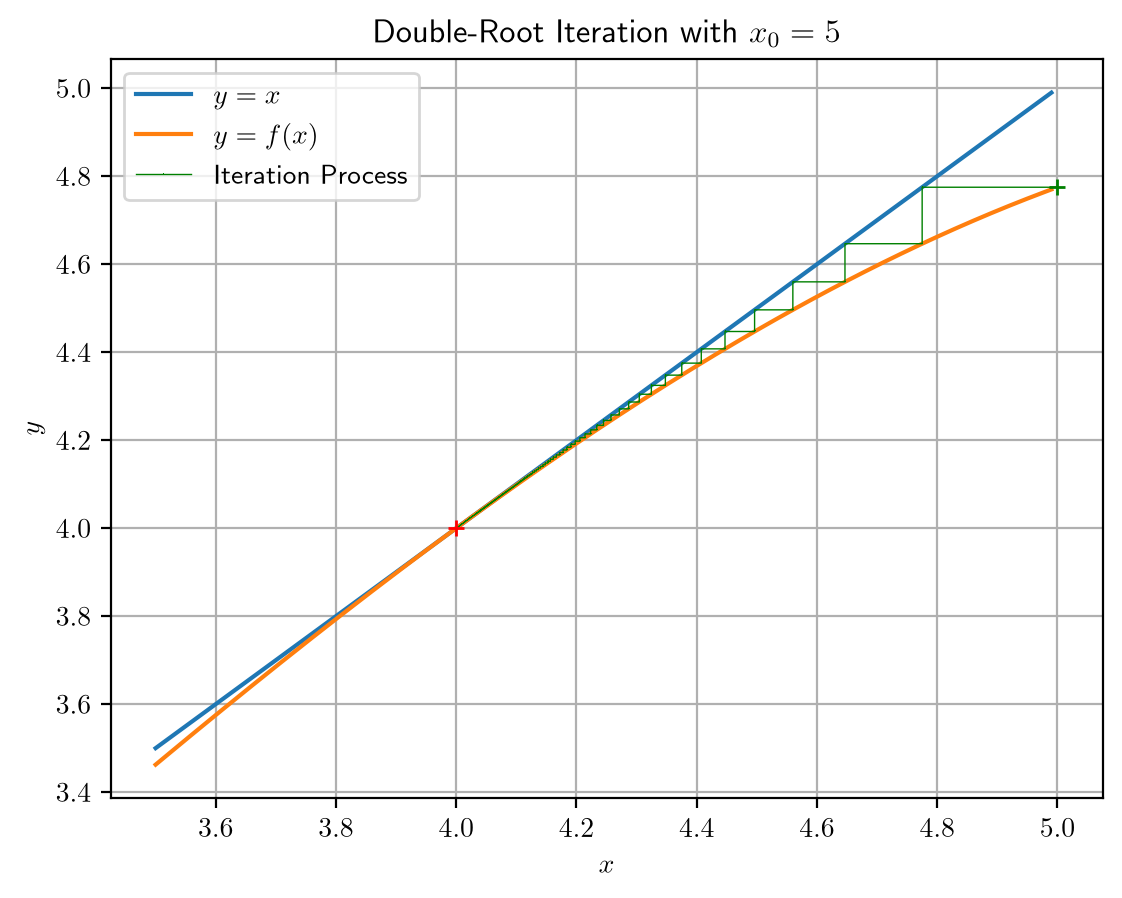

In [43]:
fig, ax = plt.subplots()
plot_fixed_point_iteration_graph(f,
                     root_estimate,
                     np.arange(3.5, 5, 0.01),
                     5,
                     4,
                     r'Double-Root Iteration with \(x_0 = 5\)')

fig.savefig('../fig/question-4')

In [44]:
d2: float = d2f(4)
d2

-0.35

In [45]:
np.sqrt(2 * (1e-5) / np.abs(d2))

np.float64(0.007559289460184545)

## Programming Task: Newton-Raphson

In [46]:
def newton_raphson_iteration(
    function: Callable[[float], float], # function for newton-raphson iteration
    derivative: Callable[[float], float], # derivative for newton-raphson iteration
    x: float, # starting value
    term_difference: float = 1e-5, # end term difference
    max_iteration: int = 1000 # max iterations
) -> list[IterationProcess]:
    return fixed_point_iteration(lambda x: x - function(x) / derivative(x), x, term_difference=term_difference, max_iteration=max_iteration)

## Question 5

In [ ]:
def intermediate_data(function,
                      root_estimate: pd.DataFrame,
                      root: float) -> pd.DataFrame:
    intermediate_data: pd.DataFrame = truncation_errors(function, root_estimate, root)
    intermediate_data["truncation_ratio_squared"] = intermediate_data["truncation_error"] / np.pow(intermediate_data["truncation_error"].shift(1), 2)

    return intermediate_data

In [48]:
def tangents_verticals(function, derivative, root_estimate: pd.DataFrame, length: int=-1):
    if length == -1:
        length = len(root_estimate.index)
    tangents = []
    verticals = []

    for i in range(length - 1):
        x: float = root_estimate.current_root_estimate[i]
        fx: float = function(x)
        dx: float = derivative(x)

        verticals.append([[x, fx], [x, 0]])
        tangents.append([[x - fx / dx, 0], [x, fx]])

    return (tangents, verticals)

In [49]:
def plot_newton_raphson_graph(function, derivative, root_estimate: pd.DataFrame,
                              x: npt.ArrayLike, initial_guess: float, root: float,
                              title: str, length: int = -1) -> None:
    tangents, verticals = tangents_verticals(function, derivative, root_estimate, length)

    y: npt.ArrayLike = function(x)

    ax.plot(x, y, label=r'\(y = f\pqty{x}\)')

    ax.plot(initial_guess, function(initial_guess), marker='+')

    ax.add_collection(mcl.LineCollection(tangents, color='g'))
    ax.add_collection(mcl.LineCollection(verticals, color='y', linestyles='dotted'))

    ax.plot(root, 0, marker='+', color='r')

    ax.set(xlabel=r'\(x\)',
           ylabel=r'\(y\)',
           title=title)
    ax.grid()
    ax.legend()

### Equation 4

In [50]:
f = lambda x: 2 * x - 3 * np.sin(x) + 5
df = lambda x: 2 - 3 * np.cos(x)
d2f = lambda x: 3 * np.sin(x)

In [51]:
root_estimate = pd.DataFrame(newton_raphson_iteration(f, df, -10, max_iteration=100))
root_estimate

,iteration,current_root_estimate
0,0,-1.000000e+01
1,1,-6.318071e+00
2,2,-1.386335e+01
3,3,2.824806e+00
4,4,8.219982e-01
...,...,...
96,96,2.101970e+17
97,97,1.260311e+17
98,98,7.511815e+16
99,99,2.404923e+17


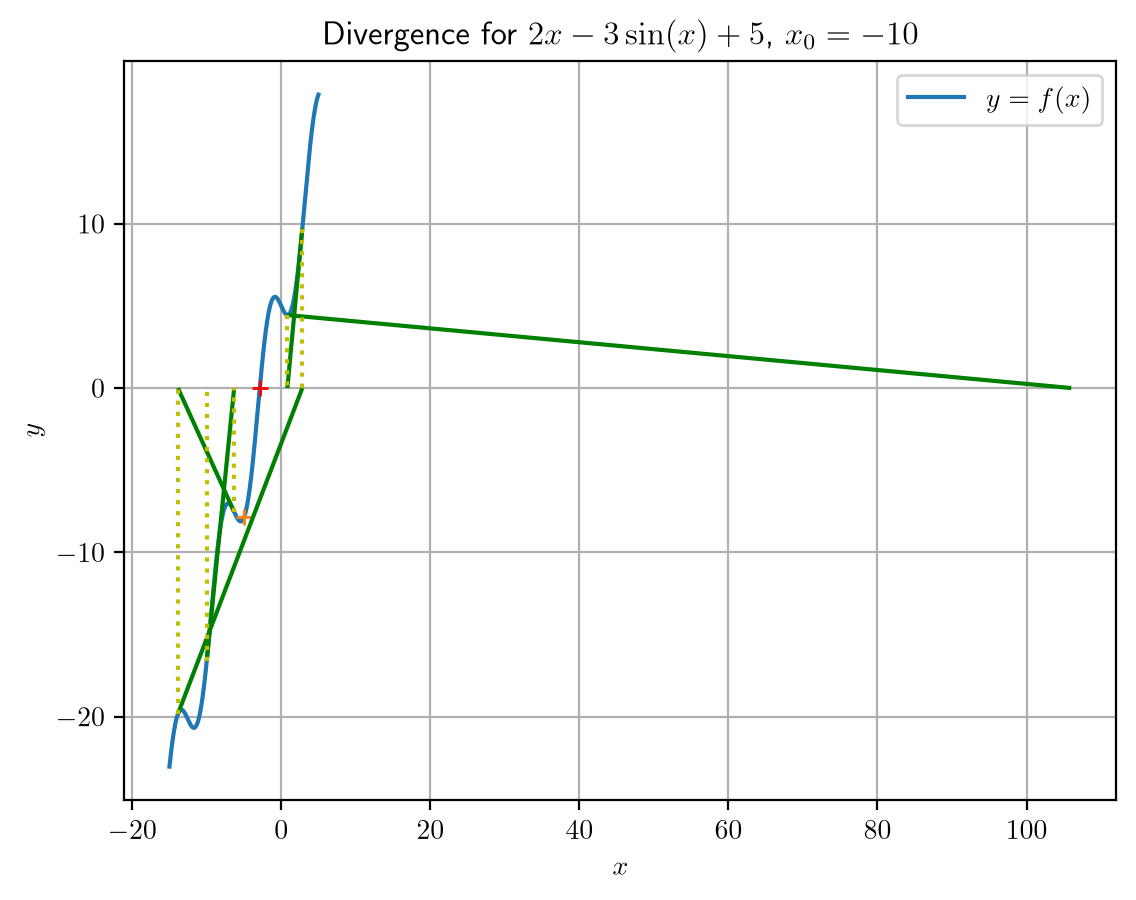

In [52]:
fig, ax = plt.subplots()
plot_newton_raphson_graph(f, df, root_estimate, np.arange(-15, 5, 0.01), -5, x_ast, r'Divergence for \(2x - 3 \sin\pqty{x} + 5\), \(x_0 = -10\)', 6)
fig.savefig('../fig/question-5-eq-4-1-diverge')

In [53]:
data: pd.DataFrame = intermediate_data(f, root_estimate, x_ast)
data.to_csv('../data/question-5-eq-4-1-diverge.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio,truncation_ratio_squared
0,-1.000000e+01,-1.663206e+01,-7.116763e+00,NaN,NaN
1,-6.318071e+00,-7.531506e+00,-3.434834e+00,0.482640,-6.781734e-02
2,-1.386335e+01,-1.983846e+01,-1.098011e+01,3.196694,-9.306690e-01
3,2.824806e+00,9.715068e+00,5.708043e+00,-0.519853,4.734495e-02
4,8.219982e-01,4.446474e+00,3.705235e+00,0.649125,1.137212e-01
...,...,...,...,...,...
96,2.101970e+17,4.203940e+17,2.101970e+17,-0.181175,1.561603e-19
97,1.260311e+17,2.520621e+17,1.260311e+17,0.599585,2.852492e-18
98,7.511815e+16,1.502363e+17,7.511815e+16,0.596029,4.729222e-18
99,2.404923e+17,4.809846e+17,2.404923e+17,3.201521,4.261980e-17


In [54]:
root_estimate = pd.DataFrame(newton_raphson_iteration(f, df, -2, 1e-20))
root_estimate

,iteration,current_root_estimate
0,0,-2.000000
1,1,-3.147594
2,2,-2.884953
3,3,-2.883237
4,4,-2.883237
5,5,-2.883237
6,6,-2.883237


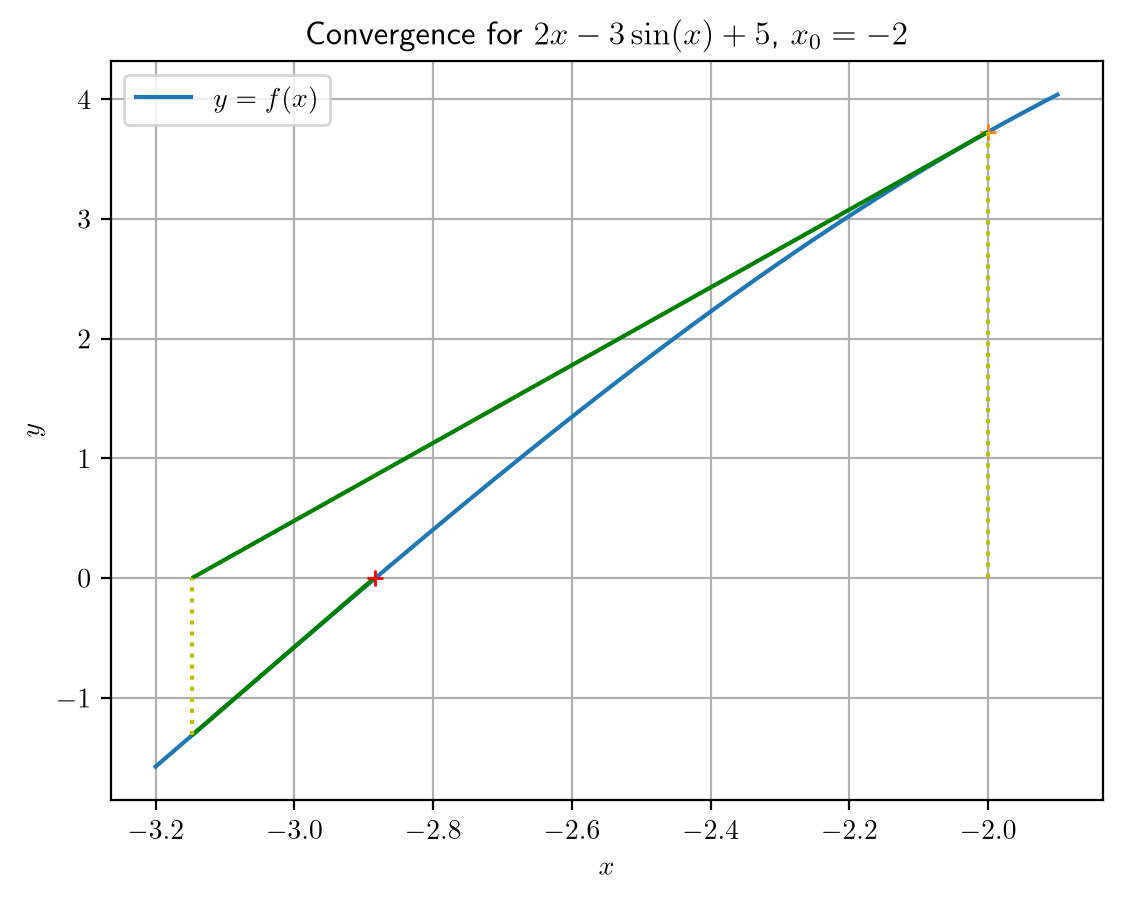

In [55]:
fig, ax = plt.subplots()
plot_newton_raphson_graph(f, df, root_estimate, np.arange(-3.2, -1.9, 0.01), -2, x_ast, r'Convergence for \(2x - 3 \sin\pqty{x} + 5\), \(x_0 = -2\)', 6)
fig.savefig('../fig/question-5-eq-4-2-converge')

In [56]:
data: pd.DataFrame = intermediate_data(f, root_estimate, x_ast)
data.to_csv('../data/question-5-eq-4-2-converge.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio,truncation_ratio_squared
0,-2.000000,3.727892e+00,8.832369e-01,NaN,NaN
1,-3.147594,-1.313194e+00,-2.643576e-01,-2.993054e-01,-0.338873
2,-2.884953,-8.409796e-03,-1.715903e-03,6.490841e-03,-0.024553
3,-2.883237,-1.123187e-06,-2.292016e-07,1.335749e-04,-0.077845
4,-2.883237,-1.953993e-14,-3.996803e-15,1.743794e-08,-0.076081
5,-2.883237,0.000000e+00,0.000000e+00,-0.000000e+00,0.000000
6,-2.883237,0.000000e+00,0.000000e+00,NaN,NaN


In [57]:
root_estimate = pd.DataFrame(newton_raphson_iteration(f, df, -6))
root_estimate

,iteration,current_root_estimate
0,0,-6.000000
1,1,-14.901931
2,2,-9.349154
3,3,-6.650195
4,4,-15.677677
...,...,...
137,137,-1.812340
138,138,-3.390284
139,139,-2.877015
140,140,-2.883240


In [58]:
data: pd.DataFrame = intermediate_data(f, root_estimate, x_ast)
data.to_csv('../data/question-5-eq-4-3-converge-slow.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio,truncation_ratio_squared
0,-6.000000,-7.838246e+00,-3.116763e+00,NaN,NaN
1,-14.901931,-2.263922e+01,-1.201869e+01,3.856146e+00,-1.237228
2,-9.349154,-1.347165e+01,-6.465917e+00,5.379883e-01,-0.044763
3,-6.650195,-7.223912e+00,-3.766958e+00,5.825869e-01,-0.090101
4,-15.677677,-2.626451e+01,-1.279444e+01,3.396491e+00,-0.901654
...,...,...,...,...,...
137,-1.812340,4.288230e+00,1.070897e+00,4.058333e-02,0.001538
138,-3.390284,-2.518978e+00,-5.070476e-01,-4.734793e-01,-0.442133
139,-2.877015,3.047704e-02,6.222306e-03,-1.227164e-02,0.024202
140,-2.883240,-1.508544e-05,-3.078388e-06,-4.947343e-04,-0.079510


In [59]:
d2f(x_ast) / (2 * df(x_ast))

np.float64(-0.07820467826700771)

### Equation 5

In [60]:
f = lambda x: np.pow(x, 3) - 8.5 * np.pow(x, 2) + 20 * x - 8
df = lambda x: 3 * np.pow(x, 2) - 17 * x + 20

In [61]:
root_estimate = pd.DataFrame(newton_raphson_iteration(f, df, 5, 1e-20))
root_estimate

,iteration,current_root_estimate
0,0,5.000000
1,1,4.550000
2,2,4.292486
3,3,4.151673
4,4,4.077379
5,5,4.039104
6,6,4.019659
7,7,4.009857
8,8,4.004935
9,9,4.002469


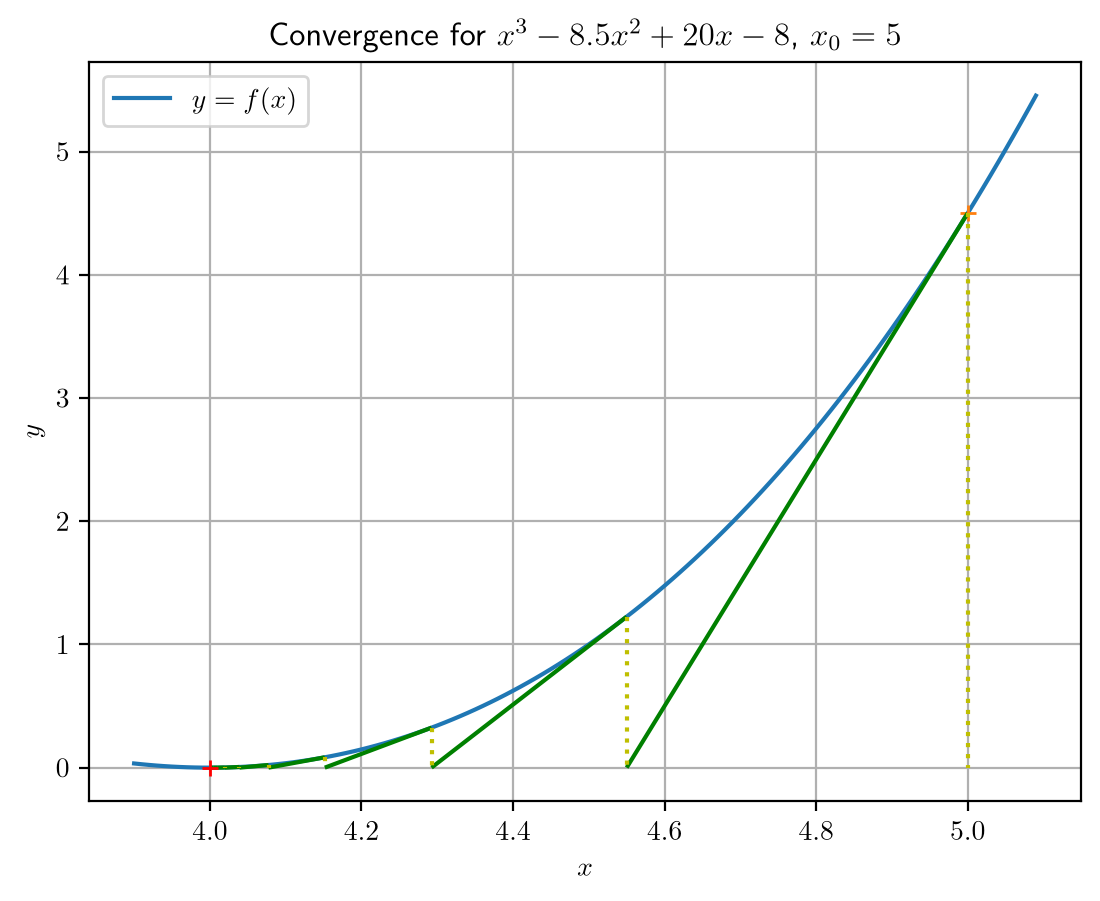

In [62]:
fig, ax = plt.subplots()
plot_newton_raphson_graph(f, df, root_estimate, np.arange(3.9, 5.1, 0.01), 5, 4, r'Convergence for \(x^3 - 8.5 x^2 + 20 x - 8\), \(x_0 = 5\)', 19)
fig.savefig('../fig/question-5-eq-5')

In [63]:
data: pd.DataFrame = intermediate_data(f, root_estimate, 4)
data.to_csv('../data/question-5-eq-5.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio,truncation_ratio_squared
0,5.000000,4.500000e+00,1.000000e+00,NaN,NaN
1,4.550000,1.225125e+00,5.500000e-01,0.550000,5.500000e-01
2,4.292486,3.244388e-01,2.924855e-01,0.531792,9.668944e-01
3,4.151673,8.400528e-02,1.516727e-01,0.518565,1.772958e+00
4,4.077379,2.141972e-02,7.737924e-02,0.510173,3.363641e+00
5,4.039104,5.411606e-03,3.910357e-02,0.505350,6.530818e+00
6,4.019659,1.360293e-03,1.965921e-02,0.502747,1.285681e+01
7,4.009857,3.410178e-04,9.856979e-03,0.501392,2.550421e+01
8,4.004935,8.537383e-05,4.935400e-03,0.500701,5.079661e+01
9,4.002469,2.135846e-05,2.469436e-03,0.500352,1.013802e+02


## Cleanup

In [64]:
plt.close('all')